In [1]:
#assignment 07

In [2]:
#question1

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [55]:
import warnings 
warnings.filterwarnings(action="ignore")

In [56]:
df=pd.read_csv("C:\\Users\\athar\\OneDrive\\Desktop\\DSML\\IIT-08-A-DS\\Datasets\\Claimants.csv")
df.head()

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0,0.0,1.0,0.0,50.0,34.940
1,1,1.0,0.0,0.0,18.0,0.891
2,1,0.0,1.0,0.0,5.0,0.330
3,0,0.0,1.0,1.0,31.0,0.037
4,1,0.0,1.0,0.0,30.0,0.038


In [57]:
df.describe()

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1340.000000,1328.000000,1299.000000,1292.000000,1151.000000,1340.000000
mean,0.488806,0.558735,0.907621,0.017028,28.414422,3.806307
std,0.500061,0.496725,0.289671,0.129425,20.304451,10.636903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,0.000000,9.000000,0.400000
50%,0.000000,1.000000,1.000000,0.000000,30.000000,1.069500
75%,1.000000,1.000000,1.000000,0.000000,43.000000,3.781500
max,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ATTORNEY  1340 non-null   int64  
 1   CLMSEX    1328 non-null   float64
 2   CLMINSUR  1299 non-null   float64
 3   SEATBELT  1292 non-null   float64
 4   CLMAGE    1151 non-null   float64
 5   LOSS      1340 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 62.9 KB


In [59]:
df.isna().sum()

ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

In [60]:
df_new=df.dropna(axis=0,inplace=True)
df_new

In [61]:
df.isna().sum()

ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

In [62]:
df.corr()

,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
ATTORNEY,1.000000,0.097475,0.084609,-0.060795,0.001132,-0.225769
CLMSEX,0.097475,1.000000,0.058164,-0.017814,-0.017942,-0.029742
CLMINSUR,0.084609,0.058164,1.000000,0.021217,0.048166,0.019502
SEATBELT,-0.060795,-0.017814,0.021217,1.000000,-0.028343,0.131182
CLMAGE,0.001132,-0.017942,0.048166,-0.028343,1.000000,0.065513
LOSS,-0.225769,-0.029742,0.019502,0.131182,0.065513,1.000000


In [63]:
x=df[['CLMSEX','CLMINSUR','SEATBELT','CLMAGE','LOSS']]
y=df['ATTORNEY']

In [64]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,random_state=123456)

In [65]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=60,max_depth=10)
model.fit(x_train,y_train)

RandomForestClassifier(max_depth=10, n_estimators=60)

In [66]:
from sklearn.model_selection import GridSearchCV

parameters = {
    'n_estimators':[50,60,70,80,90],
    'max_depth':[5,10,15,20,25,30,35,40,45]
}

grid_search = GridSearchCV(model,param_grid=parameters)

grid_search.fit(x_train,y_train)

GridSearchCV(estimator=RandomForestClassifier(max_depth=10, n_estimators=60),
             param_grid={'max_depth': [5, 10, 15, 20, 25, 30, 35, 40, 45],
                         'n_estimators': [50, 60, 70, 80, 90]})

In [67]:
grid_search.best_params_

{'max_depth': 5, 'n_estimators': 60}

In [68]:
y_prediction=model.predict(x_test)
print(x_test)

      CLMSEX  CLMINSUR  SEATBELT  CLMAGE   LOSS
1194     1.0       1.0       0.0     7.0  0.599
464      0.0       1.0       0.0    30.0  0.500
1230     1.0       1.0       0.0    39.0  0.944
719      1.0       1.0       0.0    33.0  0.781
1028     1.0       1.0       0.0    10.0  0.946
...      ...       ...       ...     ...    ...
516      1.0       1.0       0.0    64.0  0.131
341      1.0       1.0       0.0    41.0  4.691
525      0.0       1.0       0.0    13.0  0.085
280      1.0       1.0       0.0    69.0  1.076
1331     1.0       1.0       0.0     3.0  0.950

[220 rows x 5 columns]


In [69]:
print(y_test)

1194    1
464     1
1230    1
719     1
1028    1
       ..
516     1
341     1
525     1
280     0
1331    0
Name: ATTORNEY, Length: 220, dtype: int64


In [70]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_prediction)
cm

array([[86, 30],
       [39, 65]])

In [20]:
from sklearn.metrics import accuracy_score
acc_score=accuracy_score(y_test,y_prediction)
print(f"accuracy score={acc_score * 100:.2f}%")

accuracy score=68.18%


In [21]:
from sklearn.metrics import precision_score
pre_score=precision_score(y_test,y_prediction)
print(f"precision score={pre_score * 100:.2f}%")

precision score=66.67%


In [22]:
from sklearn.metrics import recall_score
rcl_score=recall_score(y_test,y_prediction)
print(f"recall score={rcl_score * 100:.2f}%")

recall score=65.38%


In [23]:
from sklearn.metrics import f1_score
f1_score=f1_score(y_test,y_prediction)
print(f"f1 score={f1_score * 100:.2f}%")

f1 score=66.02%


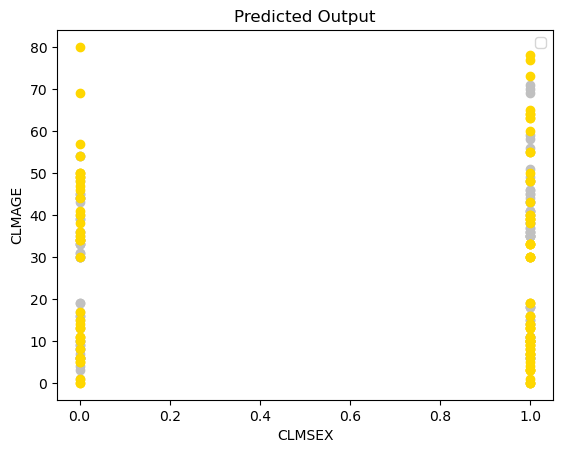

In [24]:
plt.scatter(x_test['CLMSEX'][y_prediction==0],x_test['CLMAGE'][y_prediction==0],color="silver")
plt.scatter(x_test['CLMSEX'][y_prediction==1],x_test['CLMAGE'][y_prediction==1],color="gold")
plt.xlabel("CLMSEX")
plt.ylabel("CLMAGE")
plt.title("Predicted Output")
plt.legend()

In [106]:
#question 

In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [28]:
import warnings 
warnings.filterwarnings(action="ignore")

In [29]:
df=pd.read_csv("C:\\Users\\athar\\OneDrive\\Desktop\\DSML\\IIT-08-A-DS\\Datasets\\framingham.csv")
df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [30]:
df.describe()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4240.000000,4240.000000,4135.000000,4240.000000,4211.000000,4187.000000,4240.000000,4240.000000,4240.000000,4190.000000,4240.000000,4240.000000,4221.000000,4239.000000,3852.000000,4240.000000
mean,0.429245,49.580189,1.979444,0.494104,9.005937,0.029615,0.005896,0.310613,0.025708,236.699523,132.354599,82.897759,25.800801,75.878981,81.963655,0.151887
std,0.495027,8.572942,1.019791,0.500024,11.922462,0.169544,0.076569,0.462799,0.158280,44.591284,22.033300,11.910394,4.079840,12.025348,23.954335,0.358953
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,90.000000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
 15  TenYearCHD       4240 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 530.1 KB


In [32]:
df.corr()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
male,1.000000,-0.029014,0.017415,0.197026,0.317143,-0.052504,-0.004550,0.005853,0.015693,-0.070413,-0.035879,0.058199,0.081871,-0.116932,0.005979,0.088374
age,-0.029014,1.000000,-0.166356,-0.213662,-0.192959,0.123052,0.057679,0.306799,0.101314,0.262554,0.394053,0.205586,0.136096,-0.012843,0.122356,0.225408
education,0.017415,-0.166356,1.000000,0.018528,0.008323,-0.010898,-0.035142,-0.081726,-0.038749,-0.023613,-0.129496,-0.061919,-0.137747,-0.054182,-0.035843,-0.054248
currentSmoker,0.197026,-0.213662,0.018528,1.000000,0.769774,-0.048927,-0.032980,-0.103710,-0.044285,-0.046488,-0.130281,-0.107933,-0.167857,0.062686,-0.056726,0.019448
cigsPerDay,0.317143,-0.192959,0.008323,0.769774,1.000000,-0.046155,-0.032711,-0.066645,-0.037089,-0.026479,-0.088797,-0.056715,-0.093293,0.075564,-0.058886,0.057755
BPMeds,-0.052504,0.123052,-0.010898,-0.048927,-0.046155,1.000000,0.117370,0.261067,0.052060,0.080623,0.254194,0.194122,0.100702,0.015230,0.051197,0.087519
prevalentStroke,-0.004550,0.057679,-0.035142,-0.032980,-0.032711,0.117370,1.000000,0.074791,0.006955,0.000105,0.057000,0.045153,0.025909,-0.017674,0.018440,0.061823
prevalentHyp,0.005853,0.306799,-0.081726,-0.103710,-0.066645,0.261067,0.074791,1.000000,0.077752,0.163632,0.696656,0.615840,0.301344,0.146815,0.086656,0.177458
diabetes,0.015693,0.101314,-0.038749,-0.044285,-0.037089,0.052060,0.006955,0.077752,1.000000,0.040348,0.111265,0.050260,0.087068,0.048986,0.617630,0.097344
totChol,-0.070413,0.262554,-0.023613,-0.046488,-0.026479,0.080623,0.000105,0.163632,0.040348,1.000000,0.208734,0.164698,0.115992,0.091127,0.046538,0.082369


In [33]:
df.isna().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

In [34]:
df_new=df.dropna(axis=0,inplace=True)
df_new

In [35]:
df.isna().sum()

male               0
age                0
education          0
currentSmoker      0
cigsPerDay         0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
diabetes           0
totChol            0
sysBP              0
diaBP              0
BMI                0
heartRate          0
glucose            0
TenYearCHD         0
dtype: int64

In [36]:
x=df.drop("TenYearCHD",axis=1)
y=df["TenYearCHD"]

In [37]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,random_state=123456)

In [38]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=60,max_depth=10)
model.fit(x_train,y_train)

RandomForestClassifier(max_depth=10, n_estimators=60)

In [39]:
from sklearn.model_selection import GridSearchCV

parameters = {
    'n_estimators':[50,60,70,80,90],
    'max_depth':[5,10,15,20,25,30,35,40,45]
}

grid_search = GridSearchCV(model,param_grid=parameters)

grid_search.fit(x_train,y_train)

GridSearchCV(estimator=RandomForestClassifier(max_depth=10, n_estimators=60),
             param_grid={'max_depth': [5, 10, 15, 20, 25, 30, 35, 40, 45],
                         'n_estimators': [50, 60, 70, 80, 90]})

In [40]:
grid_search.best_params_

{'max_depth': 20, 'n_estimators': 70}

In [41]:
y_prediction=model.predict(x_test)
print(x_test)

      male  age  education  currentSmoker  cigsPerDay  BPMeds  \
774      0   54        2.0              0         0.0     0.0   
1817     0   64        4.0              1         9.0     0.0   
224      0   43        1.0              0         0.0     0.0   
437      1   45        1.0              1        30.0     0.0   
3886     1   65        4.0              0         0.0     0.0   
...    ...  ...        ...            ...         ...     ...   
2635     0   41        1.0              0         0.0     0.0   
3286     0   56        1.0              0         0.0     0.0   
1773     1   48        3.0              0         0.0     0.0   
1402     0   65        1.0              0         0.0     0.0   
1754     0   36        1.0              1        15.0     0.0   

      prevalentStroke  prevalentHyp  diabetes  totChol  sysBP  diaBP    BMI  \
774                 0             0         0    193.0  118.0   84.0  24.90   
1817                0             0         0    342.0  128.0

In [42]:
print(y_test)

774     0
1817    0
224     0
437     0
3886    0
       ..
2635    0
3286    0
1773    0
1402    0
1754    0
Name: TenYearCHD, Length: 732, dtype: int64


In [43]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_prediction)
cm

array([[621,   2],
       [109,   0]])

In [44]:
from sklearn.metrics import accuracy_score
acc_score=accuracy_score(y_test,y_prediction)
print(f"accuracy score={acc_score * 100:.2f}%")

accuracy score=84.84%


In [45]:
from sklearn.metrics import precision_score
pre_score=precision_score(y_test,y_prediction)
print(f"precision score={pre_score * 100:.2f}%")

precision score=0.00%


In [46]:
from sklearn.metrics import recall_score
rcl_score=recall_score(y_test,y_prediction)
print(f"recall score={rcl_score * 100:.2f}%")

recall score=0.00%


In [47]:
from sklearn.metrics import f1_score
f1_score=f1_score(y_test,y_prediction)
print(f"f1 score={f1_score * 100:.2f}%")

f1 score=0.00%


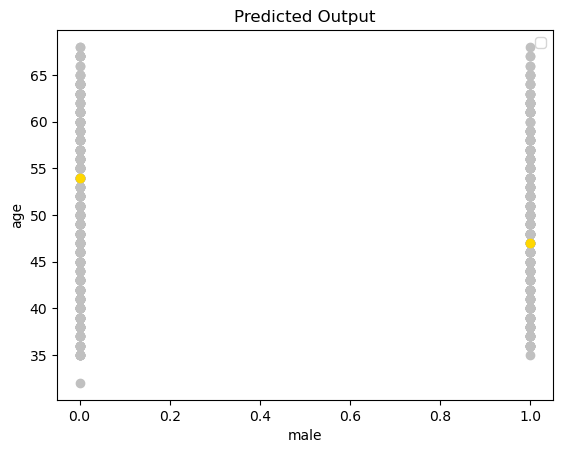

In [48]:
plt.scatter(x_test['male'][y_prediction==0],x_test['age'][y_prediction==0],color="silver")
plt.scatter(x_test['male'][y_prediction==1],x_test['age'][y_prediction==1],color="gold")
plt.xlabel("male")
plt.ylabel("age")
plt.title("Predicted Output")
plt.legend()

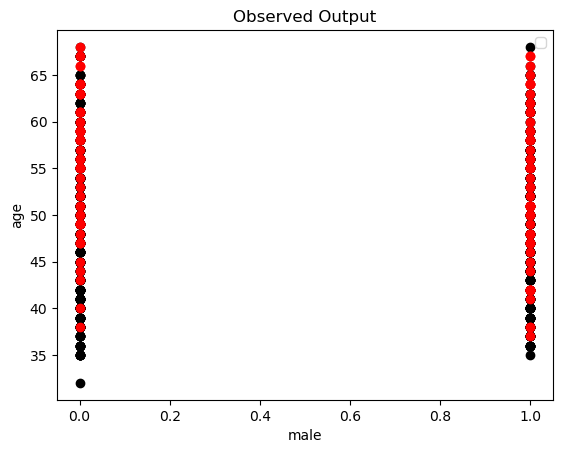

In [49]:
plt.scatter(x_test['male'][y_test==0],x_test['age'][y_test==0],color="black")
plt.scatter(x_test['male'][y_test==1],x_test['age'][y_test==1],color="red")
plt.xlabel("male")
plt.ylabel("age")
plt.title("Observed Output")
plt.legend()

In [71]:
#question 3

In [72]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 


In [73]:
import warnings
warnings.filterwarnings(action='ignore')

In [74]:
df=pd.read_csv("C:\\Users\\athar\\OneDrive\\Desktop\\DSML\\IIT-08-A-DS\\Datasets\\Zoo.csv")
df.head()

,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
0,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


In [75]:
df.describe()

,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
count,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000
mean,0.425743,0.198020,0.584158,0.405941,0.237624,0.356436,0.554455,0.603960,0.821782,0.792079,0.079208,0.168317,2.841584,0.742574,0.128713,0.435644,2.831683
std,0.496921,0.400495,0.495325,0.493522,0.427750,0.481335,0.499505,0.491512,0.384605,0.407844,0.271410,0.376013,2.033385,0.439397,0.336552,0.498314,2.102709
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,1.000000
50%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,0.000000,2.000000
75%,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,1.000000,4.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.000000,1.000000,1.000000,1.000000,7.000000


In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 17 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   hair      101 non-null    int64
 1   feathers  101 non-null    int64
 2   eggs      101 non-null    int64
 3   milk      101 non-null    int64
 4   airborne  101 non-null    int64
 5   aquatic   101 non-null    int64
 6   predator  101 non-null    int64
 7   toothed   101 non-null    int64
 8   backbone  101 non-null    int64
 9   breathes  101 non-null    int64
 10  venomous  101 non-null    int64
 11  fins      101 non-null    int64
 12  legs      101 non-null    int64
 13  tail      101 non-null    int64
 14  domestic  101 non-null    int64
 15  catsize   101 non-null    int64
 16  type      101 non-null    int64
dtypes: int64(17)
memory usage: 13.5 KB


In [77]:
df.isna().sum()

hair        0
feathers    0
eggs        0
milk        0
airborne    0
aquatic     0
predator    0
toothed     0
backbone    0
breathes    0
venomous    0
fins        0
legs        0
tail        0
domestic    0
catsize     0
type        0
dtype: int64

In [78]:
df.corr()

,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
hair,1.000000,-0.427851,-0.817382,0.878503,-0.198431,-0.473554,-0.154769,0.492531,0.191681,0.441149,-0.104245,-0.280313,0.394009,0.048973,0.207208,0.455020,-0.562384
feathers,-0.427851,1.000000,0.419248,-0.410761,0.656553,-0.058552,-0.104430,-0.613631,0.231403,0.254588,-0.145739,-0.223541,-0.206686,0.292569,0.031586,-0.135934,-0.197520
eggs,-0.817382,0.419248,1.000000,-0.938848,0.376646,0.376244,0.011605,-0.642150,-0.340420,-0.382777,0.098689,0.164796,-0.224918,-0.221090,-0.155610,-0.514650,0.661825
milk,0.878503,-0.410761,-0.938848,1.000000,-0.366765,-0.362613,-0.029721,0.628168,0.384958,0.423527,-0.242449,-0.156328,0.214196,0.210026,0.163928,0.574906,-0.723683
airborne,-0.198431,0.656553,0.376646,-0.366765,1.000000,-0.172638,-0.295181,-0.594311,-0.104718,0.286039,0.008528,-0.251157,0.043712,0.009482,0.063274,-0.349768,0.022677
aquatic,-0.473554,-0.058552,0.376244,-0.362613,-0.172638,1.000000,0.375978,0.053150,0.022463,-0.637506,0.087915,0.604492,-0.360638,-0.034642,-0.224308,-0.111866,0.326639
predator,-0.154769,-0.104430,0.011605,-0.029721,-0.295181,0.375978,1.000000,0.129452,0.051022,-0.262931,0.115391,0.190302,-0.099723,0.018947,-0.309794,0.144790,0.061179
toothed,0.492531,-0.613631,-0.642150,0.628168,-0.594311,0.053150,0.129452,1.000000,0.575085,-0.065690,-0.062344,0.364292,-0.193476,0.310368,0.069430,0.344010,-0.471527
backbone,0.191681,0.231403,-0.340420,0.384958,-0.104718,0.022463,0.051022,0.575085,1.000000,0.207666,-0.246611,0.209499,-0.432856,0.731762,0.101733,0.356976,-0.828845
breathes,0.441149,0.254588,-0.382777,0.423527,0.286039,-0.637506,-0.262931,-0.065690,0.207666,1.000000,-0.120752,-0.617219,0.369868,0.088952,0.124068,0.204125,-0.519308


In [79]:
x=df.drop('type',axis=1)
y=df['type']

In [80]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.7,random_state=123456)

In [81]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=60,max_depth=10)
model.fit(x_train,y_train)

RandomForestClassifier(max_depth=10, n_estimators=60)

In [82]:
from sklearn.model_selection import GridSearchCV

parameters = {
    'n_estimators':[50,60,70,80,90],
    'max_depth':[5,10,15,20,25,30,35,40,45]
}

grid_search = GridSearchCV(model,param_grid=parameters)

grid_search.fit(x_train,y_train)

GridSearchCV(estimator=RandomForestClassifier(max_depth=10, n_estimators=60),
             param_grid={'max_depth': [5, 10, 15, 20, 25, 30, 35, 40, 45],
                         'n_estimators': [50, 60, 70, 80, 90]})

In [83]:
grid_search.best_params_

{'max_depth': 10, 'n_estimators': 50}

In [84]:
y_prediction=model.predict(x_test)
print(x_test)


    hair  feathers  eggs  milk  airborne  aquatic  predator  toothed  \
82     0         0     1     0         0        1         0        1   
93     1         0     0     1         1        0         0        1   
41     0         1     1     0         0        0         1        0   
23     0         1     1     0         1        0         0        0   
59     0         1     1     0         1        0         0        0   
86     0         0     1     0         0        1         1        1   
11     0         1     1     0         1        0         0        0   
95     0         1     1     0         1        0         1        0   
67     1         0     0     1         0        0         1        1   
21     0         1     1     0         1        1         0        0   
96     1         0     0     1         0        0         0        1   
99     0         0     1     0         0        0         0        0   
13     0         0     1     0         0        0         1     

In [85]:
print(y_test)

82    4
93    1
41    2
23    2
59    2
86    4
11    2
95    2
67    1
21    2
96    1
99    7
13    7
83    2
38    4
79    2
27    1
22    1
98    1
6     1
5     1
81    7
26    5
44    1
78    2
48    1
73    4
33    2
24    6
62    3
0     1
Name: type, dtype: int64


In [86]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_prediction)
cm

array([[11,  0,  0,  0,  0,  0,  0],
       [ 0, 10,  0,  0,  0,  0,  0],
       [ 0,  0,  1,  0,  0,  0,  0],
       [ 0,  0,  0,  4,  0,  0,  0],
       [ 0,  0,  0,  0,  1,  0,  0],
       [ 0,  0,  0,  0,  0,  1,  0],
       [ 0,  0,  0,  0,  0,  2,  1]])

In [87]:
from sklearn.metrics import accuracy_score
acc_score=accuracy_score(y_test,y_prediction)
print(f"accuracy score={acc_score * 100:.2f}%")

accuracy score=93.55%


In [89]:
from sklearn.metrics import precision_score
pre_score=precision_score(y_test,y_prediction,average='weighted')
print(f"precision score={pre_score * 100:2f}%")

precision score=97.849462%


In [90]:
from sklearn.metrics import recall_score
rcl_score=recall_score(y_test,y_prediction,average='weighted')
print(f"recall score={rcl_score * 100:.2f}%")

recall score=93.55%


In [91]:
from sklearn.metrics import f1_score
f1_score=f1_score(y_test,y_prediction,average='weighted')
print(f"f1 score={f1_score * 100:.2f}%")

f1 score=93.55%


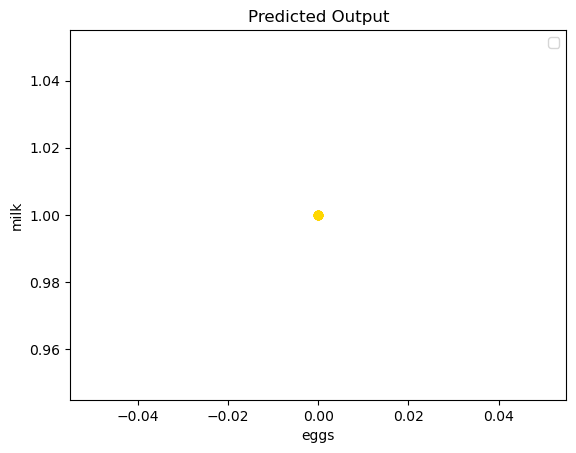

In [92]:
plt.scatter(x_test['eggs'][y_prediction==0],x_test['milk'][y_prediction==0],color="silver")
plt.scatter(x_test['eggs'][y_prediction==1],x_test['milk'][y_prediction==1],color="gold")
plt.xlabel("eggs")
plt.ylabel("milk")
plt.title("Predicted Output")
plt.legend()

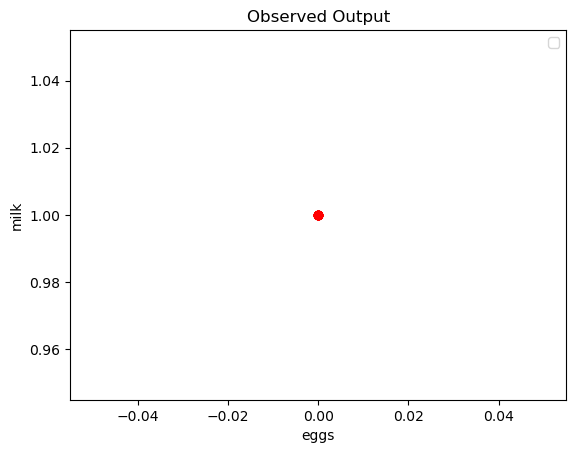

In [93]:
plt.scatter(x_test['eggs'][y_test==0],x_test['milk'][y_test==0],color="black")
plt.scatter(x_test['eggs'][y_test==1],x_test['milk'][y_test==1],color="red")
plt.xlabel("eggs")
plt.ylabel("milk")
plt.title("Observed Output")
plt.legend()